# Hälsostudie - Del2

## 1. Functions and Modules

Jag har flyttar kod från del 1 till återvändbara funktioner i python files. 

Impotertat funktionerna till notebooken för att kontrollera att de fungerar och ger samma resultat som i Del 1.

In [1]:
import sys
from pathlib import Path

# Hitta projektets huvudmapp
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

# Importera funktioner från vår modul
from src.analysis_utils import (
    load_health_data,
    calculate_summary_stats,
    calculate_disease_proportion,
    simulate_disease,
    calculate_bp_confidence_interval,
    test_smoking_bp
)

In [2]:
df = load_health_data(
    project_root / "data" / "health_study_dataset.csv"
)

print(df.shape)

(800, 9)


In [3]:
print("Current directory:", Path.cwd())
print("Project root:", project_root)
print("Module exists:", (project_root / "src" / "analysis_utils.py").exists())

Current directory: /mnt/c/Users/luisa/ECutbilding/health-study/notebooks
Project root: /mnt/c/Users/luisa/ECutbilding/health-study
Module exists: True


## Testa funktioner 

### 1. Summary

In [4]:
print("SUMMARY STATISTICS")
print(calculate_summary_stats(df))

SUMMARY STATISTICS
          age  weight  height  systolic_bp  cholesterol
mean    49.43   73.41  171.85       149.18         4.93
median  50.00   73.20  171.35       149.40         4.97
min     18.00   33.70  144.40       106.80         2.50
max     90.00  114.40  200.40       185.90         7.88


### 2. Disease proporktion

In [5]:
print("\nDISEASE PROPORTION")
disease_probability = calculate_disease_proportion(df)
print(f"Disease proportion: {disease_probability:.4%}")


DISEASE PROPORTION
Disease proportion: 5.8750%


### 3. Disease simulation

In [6]:
print("\nDISEASE SIMULATION")
simulation = simulate_disease(disease_probability, n=1000, seed=42)
print("Disease cases:", simulation.sum())
print(f"Simulated proportion: {simulation.mean():.2%}")


DISEASE SIMULATION
Disease cases: 54
Simulated proportion: 5.40%


### 4. Confidence Intervals

In [7]:
print("\nCONFIDENCE INTERVALS")
normal_ci = calculate_bp_confidence_interval(df, method="normal")
bootstrap_ci = calculate_bp_confidence_interval(df, method="bootstrap")

print("Normal:", tuple(round(x, 2) for x in normal_ci))
print("Bootstrap:", tuple(round(x, 2) for x in bootstrap_ci))


CONFIDENCE INTERVALS
Normal: (148.29, 150.07)
Bootstrap: (148.3, 150.06)


### 5. Hypothes test

In [8]:
print("\nHYPOTHESIS TESTING")
t_stat, p_value = test_smoking_bp(df)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")


HYPOTHESIS TESTING
t-statistic: 0.4503
p-value: 0.3264


### 1.1 Functiones och Modules

Jag har skapat 6 funktioner: 

- load_health_data() 
  -  Läser in datasetet.

- calculate_summary_stats() 
  -  Beräknar medelvärde, median, min och max.

- calculate_disease_proportion() 
  -  Beräknar andelen deltagare med sjukdomen.

- simulate_disease() 
  - Simulerar sjukdom med NumPy.

- calculate_bp_confidence_interval() 
  - Beräknar konfidensintervall med normalapproximation eller bootstrap.

- test_smoking_bp() 
  -  Jämför blodtryck mellan rökare och icke-rökare med Welch's t-test.

**Varför använder vi funktioner och moduler?
**
Vi använder funktioner för att undvika att upprepa samma kod och för att kunna återanvända våra analyser.

Genom att lägga funktionerna i en separat modul blir notebooken enklare att läsa och koden lättare att underhålla.

**Resultat:** Vi har testat funktionerna och fått samma statistiska resultat som i Del 1.

## 2. HealthAnalyzer Class

Klassen använder funktionerna från analysis_utils.py för att utföra olika analyser. Den kan ocksp skapa grafer. 

Använder klassen för att samla flera funktioner på ett ställe och undvika att skriva samma kod flera gånger. 

In [9]:
from src.analysis_utils import load_health_data
from src.health_analyzer import HealthAnalyzer

# Ladda dataset
df = load_health_data(
    project_root / "data" / "health_study_dataset.csv"
)
# skapa ett objekt med dataset
analyzer = HealthAnalyzer(df)

print("Dataset shape:", analyzer.df.shape)


Dataset shape: (800, 9)


In [10]:
# Testa metoder från HealthAnalyzer

display(analyzer.summary_statistics())

print("Disease proportion:", analyzer.disease_proportion())
print("Disease simulation:", analyzer.disease_simulation())

print("Normal CI:", analyzer.confidence_interval("normal"))
print("Bootstrap CI:", analyzer.confidence_interval("bootstrap"))

t, p = analyzer.smoking_bp_test()
print(f"t-statistic: {t:.4f}")
print(f"p-value: {p:.4f}")

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


Disease proportion: 0.05875
Disease simulation: 0.054
Normal CI: (148.2921066505355, 150.06514334946453)
Bootstrap CI: (148.304625, 150.06331875)
t-statistic: 0.4503
p-value: 0.3264


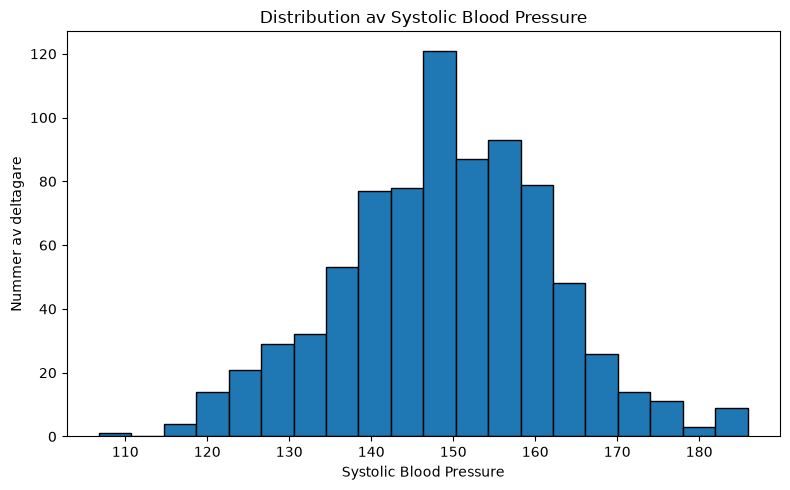

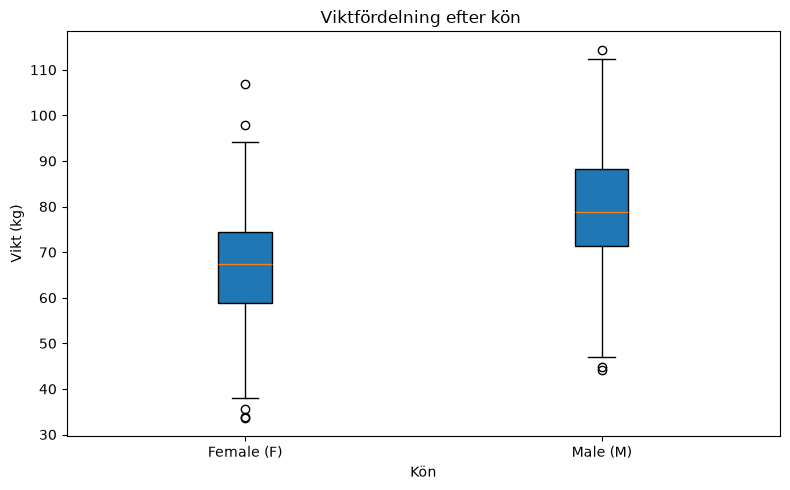

In [11]:
import matplotlib.pyplot as plt

# Histogem över bp
fig_bp = analyzer.plot_bp_distribution()
display(fig_bp)
plt.close(fig_bp)

# Boxplot över vikt per kön
fig_weight = analyzer.plot_weight_by_gender()
display(fig_weight)
plt.close(fig_weight)

### 2.1 HealthAnalyzer 

Klassen använder funktionerna från analysis_utils.py för att beräkna statistik, simulera sjukdom, beräkna konfidensintervall och utföra hypotesprövning. 

Har också lagt till två metoder för visualireing:
- histogram över bp
- boxplot över vikt per kön

Man använder en klass för att kunna arbeta med samma dataset utan att behöva skicka det till varje funktion. Det gör koden mer organiserad och enklare att återvända

## 3. Linear Algebra och Linear Regression

Ska använda linjär regression för att undersöka sambandet mellan ålder och systoliskt blodtryckt.

Använder age som oberoende variable (x) och systolic_bp som beroende (y).

Målet är att undersöka om ålder kan användas för att förutsäga blodtryck men hjälp av NUmPy.

In [12]:
import numpy as np

# Oberoende variabel (X) - ålder
X = df[["age"]].to_numpy()

# Beroende variable (y) - systoliskt blodtryck
y = df["systolic_bp"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (800, 1)
y shape: (800,)


In [13]:
# Skapa designmatris med en kolumn av ettor (intercept)
X_design = np.column_stack((
    np.ones(X.shape[0]),
    X
))

print("Originalt X shape:", X.shape)
print("Matrix shape:", X_design.shape)

print("\nFörsta 5 rader:")
print(X_design[:5])

Originalt X shape: (800, 1)
Matrix shape: (800, 2)

Första 5 rader:
[[ 1. 57.]
 [ 1. 47.]
 [ 1. 59.]
 [ 1. 72.]
 [ 1. 46.]]


In [14]:
# Beräkna koefficienterna med minsta kvadratmetoden
koefficienterna = np.linalg.lstsq(X_design, y, rcond=None)[0]

# Lutning
intercept = koefficienterna[0]
slope = koefficienterna[1]

print(f"Intercept: {intercept:.4f}")
print(f"Slope: {slope:.4f}")

Intercept: 122.6849
Slope: 0.5360


### 3.1 Linear regression

Använder np.linalg.lstsq() för att beräkna intercept och lutning med minsta kvadratmetoden. 

Meroden hittat den linje som minimerar summan av de kvadrerade skillnaderna mellan verkliga och förutsagda blodtrycksvärden. 

In [15]:
# Förutsäg blodtryck för en person som är 50 år
age_example = 50

predicted_bp = intercept + slope * age_example

print(f"Intercept: {intercept:.4f}")
print(f"Slope: {slope:.4f}")
print(f"Förutsäg av bp av ålder {age_example}: {predicted_bp:.2f}")

Intercept: 122.6849
Slope: 0.5360
Förutsäg av bp av ålder 50: 149.49


In [16]:
# Förutsäg blodtryck för alla deltagare med amtrisberäkning

# @ gör en matris-multiplikation
y_pred = X_design @ koefficienterna
#Istället för att beräkna förutsägelsen person för person med en loop
# beräkna NumPy de 800 förutsägelserna med matrisopreration

print("Nummer av förutsägs:", len(y_pred))
print("\nFörst 5 rader:")
print(y_pred[:5].round(2))

Nummer av förutsägs: 800

Först 5 rader:
[153.24 147.88 154.31 161.28 147.34]


In [17]:
# Skillnaden mellan verkliga och förutsagda värden
errors = y - y_pred

# Mean Absolute Error
mae = np.mean(np.abs(errors))

# Root Mean Squared Error
rmse = np.sqrt(np.mean(errors ** 2))

# R-squared
ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print(f"MAE: {mae:.2f} mmHg")
print(f"RMSE: {rmse:.2f} mmHg")
print(f"R^2: {r2:.4f}")

MAE: 8.09 mmHg
RMSE: 10.15 mmHg
R^2: 0.3692


### 3.3 Model 

Använder MAE, RMSE och R^2 för att utvärdera vår linjära regression. 

MAE och RMSE visar hur stora felen är mellan verkliga och förutsagda blodtrycksvärden. R^2 visar hur stor del av variationen i blodtryck som modellen kan förklara.

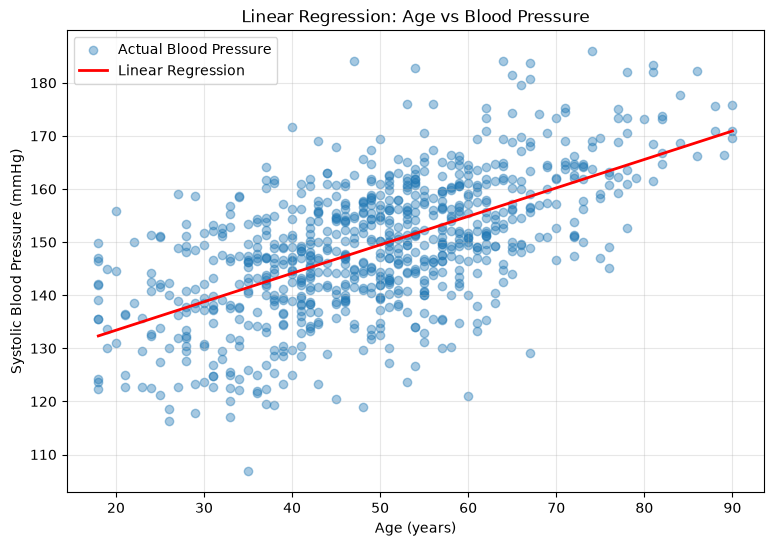

In [18]:
import matplotlib.pyplot as plt

# Skapa en scatter plot med verkliga värden
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    X.flatten(),
    y,
    alpha=0.4,
    label="Actual Blood Pressure"
)

# Sortera ålder för att rita regressionslinjen
sorted_index = np.argsort(X.flatten())

ax.plot(
    X.flatten()[sorted_index],
    y_pred[sorted_index],
    color="red",
    linewidth=2,
    label="Linear Regression"
)

ax.set_title("Linear Regression: Age vs Blood Pressure")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Systolic Blood Pressure (mmHg)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

### 3.4 Result Och interpretaktion

Den linjära regressionen visar ett **positivt samband mellan ålder och systoliskt blodtryck**.

Modellens resultat:
- **Intercept:** 112,68
- **Slope:** 0,54
- **Predicted BP at age 50:** 149,49 mmHg
- **MAE:** 8,09 mmHg
- **RMSE:** 10,15 mmHg
- **R^2:** 0,369

**Tolkning av resultaten:**

Lutningen på 0,54 betyder att modellen förutsäger att bp ökar med ungefär **0,54 mmHg för varje extra år**

MAE visar att modellen i genomsnitt har ett fel på cirka 8,09 mmHg, medan RMSE är 10,15.

R^2 är ungefär 0,369, det betyder att ålder förklarar cirka 36,9% av variationen i bp i dataset.

**I grafen**

Ser att den röda regressionslinjen stiger när åldern ökar. Det visar ett positivt samband mellan ålder och bp.

Punkterna är ganska utspridda runt linjen. Det betyder att personer i samma ålder kan ha olika bp och att ålder inte förklarar allt. 

**Slutsats:**

Ålder har ett tydligt positivit samband med systoliskt bp i dataset, men modellen har begränsad svar eftersom det finns stor variation tunt regressionslinjen.
 

## 4. Utökad abalys och visualisering

### 4.1 Disease efter kön

Kommer undersöka om andelen deltagare med sjukdomen skiljer sig mellan kvinnor och män.

Kommer använda variablerna kön och disease för att beräkna antal deltagare, antal sjukdomsfall och andelen med sjukdomen i varje grupp.

Jämför procent eftersom grupperna har olika deltagare.

In [19]:
# Beräkna sjukdomsförekomst per kön

disease_kön = df.groupby("sex")["disease"].agg(
    participants="size",
    disease_cases="sum",
    disease_proportion="mean"
)

# Omvandla andel till procent
disease_kön["disease_percentange"] = (
    disease_kön["disease_proportion"] * 100
)

display(disease_kön.round(2))

,participants,disease_cases,disease_proportion,disease_percentange
sex,,,,
F,403,18,0.04,4.47
M,397,29,0.07,7.30


In [20]:
# Kontrollera antal deltagare och sjukdomsfall
total_participants = disease_kön["participants"].sum()
total_cases = disease_kön["disease_cases"].sum()

print("Total participants:", total_participants)
print("Total disease cases:", total_cases)

Total participants: 800
Total disease cases: 47


### 4.2 Kolesterol Och Systoliskt blodtryck

Kommer använda korrelationskoefficient för att se om det finns ett linärt samband mellan variablerna. 

Korrelationskoefficienten ligger mellan -1 och 1. Positivt värde visar ett positivt samband och ett negativt värde visar negativi samband.

In [21]:
# Välj kolesterol och blodtryck
cholesterol = df["cholesterol"]
blood_pressure = df["systolic_bp"]

# Beräkna Pearson korrelation
correlation = cholesterol.corr(blood_pressure)

print(f"Korrelationskoefficiente: {correlation:.4f}")

Korrelationskoefficiente: 0.3684


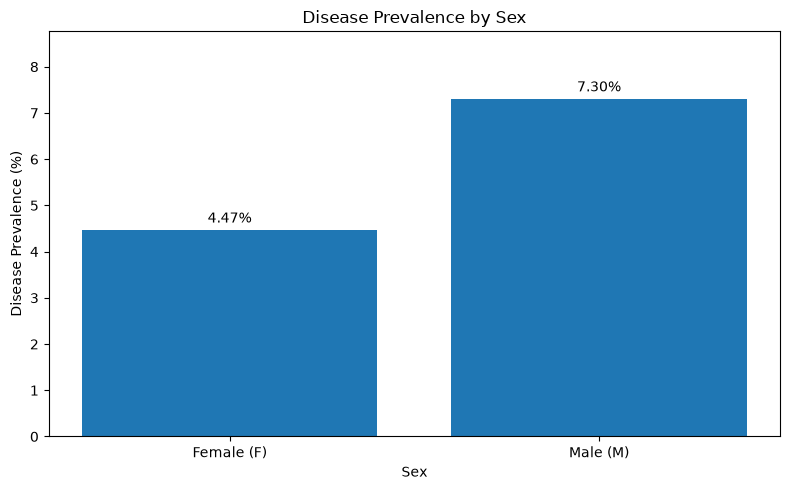

In [22]:
# Visa sjukdomsförekomst per kön
fig = analyzer.plot_disease_by_sex()

display(fig)
plt.close(fig)

### 4.3 Slutsats

**Disease efter kön**

Analysen visar att **4,47% av kvinnorna** och **7,30% av männen i dataset har sjukdomen.**

Stapeldiagrammet visar att andelen med sjukdomen är högre bland män än bland kvinnor.

**Kolesterol va Systoliskt blodtryck**

Korrelationskoefficient är **r = 0,3684**, vilket visar ett svagt till måttligt positivt linjärt samband mellan kolesterol och bp. 

Analyserna ger oss djupare förståelse av dataset.

Vi ser skillnader i sjukdomförekomst mellan kvinnor och män och ett positivt samband mellan kolesterol och blodtryckt.

### 4.4 Method Choices

Använde groupby() för att jämföra andelen deltagare med sjukdomen mellan kvinnor och män. Valde ett stapeldiagram eftersom det gör det enkelt att jämföra procent mellan grupperna.

Använde Pearsons korrelationskoefficient för att undersöka det linjära sambandet mellan kolesterol och blodtryck. Ett spridningsdiagram hjälper oss att visualisera sambandet och se hur datapunkterna är fördelade.

Dessa metoder passar våra analyser eftersom vi jämför både kategoriska och numeriska variabler.